# Machine Learning Lab 6

**Name:** Sadia Fatima
**CMS:** 023-24-0213
**Section:** G
**GitHub Profile:** https://github.com/Sadia-Farooque/Machine_Learning.git
**Kaggle Profile:** https://www.kaggle.com/anamfarooque

**Dataset:** Telco Customer Churn  
**Target Variable:** Churn  
**Problem Type:** Binary Classification



In [4]:
#task1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("clean_churn.csv")

df.head()

print("Dataset shape:", df.shape)
df.info()
df.isnull().sum()

print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)



Dataset shape: (7043, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod   

### Interpretation

The dataset was successfully loaded and its shape, data types, and missing values were verified. The target variable is Churn, which contains the two classes Yes and No. The class distribution will be considered when evaluating the models because accuracy alone may not provide a complete picture of performance.

In [5]:
# task 2 
previous_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.7984,
        0.7779
    ],
    "Precision": [
        0.6347,
        0.6034
    ],
    "Recall": [
        0.5668,
        0.4794
    ],
    "F1-score": [
        0.5989,
        0.5321
    ]
})

previous_results

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7984,0.6347,0.5668,0.5989
1,Random Forest,0.7779,0.6034,0.4794,0.5321


### Interpretation

The previous results provide baseline performance for the new models in this lab. The Decision Tree achieved an accuracy of 0.7984 and an F1-score of 0.5989, while the Random Forest achieved an accuracy of 0.7779 and an F1-score of 0.5321. These results will be used as benchmarks when evaluating Logistic Regression and KNN.

In [11]:
print(df.columns.tolist())
X = df.drop("Churn", axis=1)
y = df["Churn"]
if "customerID" in X.columns:
    X = X.drop("customerID", axis=1)
y = y.map({"No": 0, "Yes": 1})
print(y.value_counts())

X = pd.get_dummies(X, drop_first=True)
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.select_dtypes(include="object").columns)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Churn
0    5174
1    1869
Name: count, dtype: int64
X shape: (7043, 30)
y shape: (7043,)
Index([], dtype='object')


## Task 4 

Feature scaling is important for KNN because KNN calculates distances between data points. If one feature has a much larger numerical range than another, it can dominate the distance calculation. Scaling also helps Logistic Regression because it puts features on comparable scales, while Decision Trees and Random Forests do not require scaling because their splitting decisions are based on feature thresholds rather than distance.

In [13]:
# task 5 


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training samples: 5634
Testing samples: 1409
Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


### Interpretation

The data was divided into training and testing sets before feature scaling. StandardScaler was fitted only on the training features and then used to transform both the training and testing features. This prevents data leakage because information from the test set is not used when learning the scaling parameters.

In [14]:
#task 6
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train)
logreg.fit(X_train_scaled, y_train)

y_pred_lr = logreg.predict(X_test_scaled)

In [20]:
# task 7 

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
print("Logistic Regression Results")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1-score :", f1_lr)


Logistic Regression Results
Accuracy : 0.8069552874378992
Precision: 0.6583850931677019
Recall   : 0.5668449197860963
F1-score : 0.6091954022988506


### Interpretation

The Logistic Regression model achieved an accuracy of 80.70%, precision of 65.84%, recall of 56.68%, and F1-score of 60.92%. The model correctly identifies a substantial portion of the customers who churn, as reflected by its recall of 56.68%. The F1-score of 60.92% provides a balance between precision and recall and will be used alongside the other metrics when comparing Logistic Regression with KNN, Decision Tree, and Random Forest.

In [18]:
# task 8 

probabilities = logreg.predict_proba(X_test_scaled)

print(probabilities[:5])
probability_table = pd.DataFrame({
    "Actual Churn": y_test.iloc[:5].values,
    "Probability No": probabilities[:5, 0],
    "Probability Yes": probabilities[:5, 1],
    "Predicted Churn": y_pred_lr[:5]
})

probability_table


[[0.95563487 0.04436513]
 [0.31639994 0.68360006]
 [0.94356046 0.05643954]
 [0.59169375 0.40830625]
 [0.97830853 0.02169147]]


,Actual Churn,Probability No,Probability Yes,Predicted Churn
0,0,0.955635,0.044365,0
1,0,0.316400,0.683600,1
2,0,0.943560,0.056440,0
3,0,0.591694,0.408306,0
4,0,0.978309,0.021691,0


### Interpretation

The predict_proba() function returns the estimated probability for each class. The first probability corresponds to class 0 (No Churn) and the second corresponds to class 1 (Churn). The predict()function converts these probabilities into a class prediction by selecting the class with the higher probability under the model's default classification threshold.

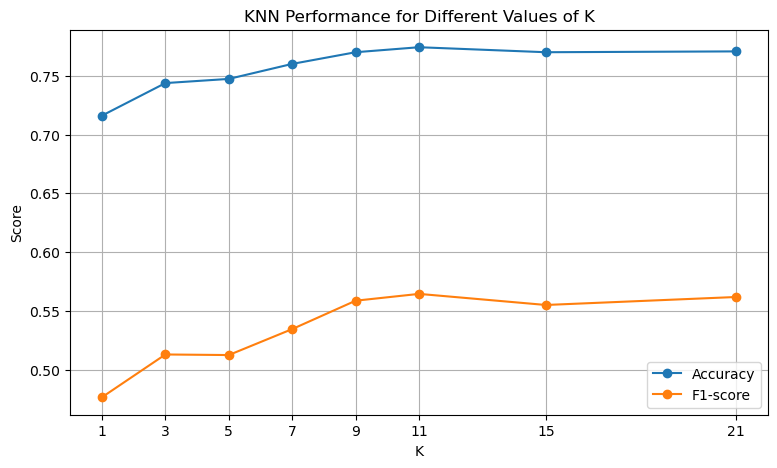

Selected K: 11
Accuracy: 0.7743080198722498
F1-score: 0.5643835616438356


In [22]:
# task 9

from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15, 21]

knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred_knn = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred_knn)
    precision = precision_score(y_test, y_pred_knn)
    recall = recall_score(y_test, y_pred_knn)
    f1 = f1_score(y_test, y_pred_knn)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

knn_results_df = pd.DataFrame(knn_results)

knn_results_df

plt.figure(figsize=(9, 5))

plt.plot(
    knn_results_df["K"],
    knn_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_results_df["K"],
    knn_results_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Performance for Different Values of K")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

best_knn_row = knn_results_df.sort_values(
    by=["F1-score", "Accuracy"],
    ascending=False
).iloc[0]

best_k = int(best_knn_row["K"])

print("Selected K:", best_k)
print("Accuracy:", best_knn_row["Accuracy"])
print("F1-score:", best_knn_row["F1-score"])

### Interpretation

The KNN classifier was evaluated using several values of K rather than relying on a single setting. Very small values of K can make the model sensitive to individual training examples and noise, while very large values can make the model overly smooth by considering many neighbors. The selected K was therefore based on the observed test-set performance, with F1-score considered alongside accuracy rather than simply choosing the smallest or largest K.

Final KNN Results
Selected K: 11
Accuracy : 0.7743080198722498
Precision: 0.5786516853932584
Recall   : 0.5508021390374331
F1-score : 0.5643835616438356
[[885 150]
 [168 206]]


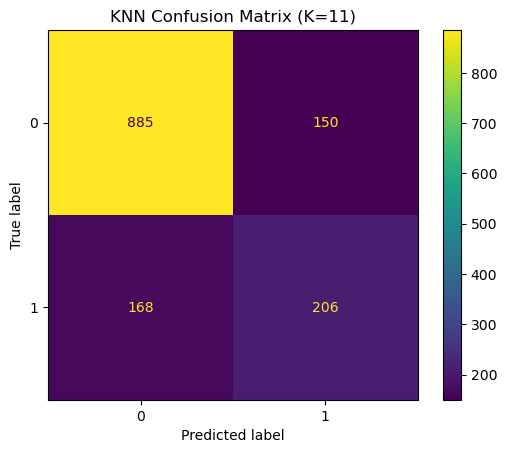

In [23]:
# task 11 
final_knn = KNeighborsClassifier(n_neighbors=best_k)

final_knn.fit(X_train_scaled, y_train)

y_pred_knn = final_knn.predict(X_test_scaled)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("Final KNN Results")
print("Selected K:", best_k)
print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1-score :", f1_knn)


cm_knn = confusion_matrix(y_test, y_pred_knn)

print(cm_knn)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn)
disp.plot()

plt.title(f"KNN Confusion Matrix (K={best_k})")
plt.show()



### Interpretation

The final KNN model was trained using the selected value of K and evaluated on the test set. The accuracy, precision, recall, and F1-score provide a complete view of its performance, while the confusion matrix shows the numbers of correct and incorrect predictions for both churn classes.

In [27]:
# task 12
comparison_df = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN"
    ],
    "Accuracy": [
        0.7984,
        0.7779,
        accuracy_lr,
        accuracy_knn
    ],
    "Precision": [
        0.6347,
        0.6034,
        precision_lr,
        precision_knn
    ],
    "Recall": [
        0.5668,
        0.4794,
        recall_lr,
        recall_knn
    ],
    "F1-score": [
        0.5989,
        0.5321,
        f1_lr,
        f1_knn
    ]
})

comparison_df
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for metric in metrics:
    best_model = comparison_df.loc[
        comparison_df[metric].idxmax(),
        "Model"
    ]

    best_value = comparison_df[metric].max()

    print(f"Highest {metric}: {best_model} ({best_value:.4f})")

    overall_model = comparison_df.loc[
    comparison_df["F1-score"].idxmax(),
    "Model"
]

overall_f1 = comparison_df["F1-score"].max()

print("Highest F1-score model:", overall_model)
print("F1-score:", overall_f1)


Highest Accuracy: Logistic Regression (0.8070)
Highest Precision: Logistic Regression (0.6584)
Highest Recall: Logistic Regression (0.5668)
Highest F1-score: Logistic Regression (0.6092)
Highest F1-score model: Logistic Regression
F1-score: 0.6091954022988506


### Interpretation

The four models were evaluated using the same test set and the same four metrics. The results show that model performance can change depending on the metric being considered. Because the dataset contains more non-churn customers than churn customers, accuracy alone should not be used to judge the models. Precision, recall, and especially F1-score provide additional information about how well the models identify the churn class.

In [28]:
# task 14

coefficients = logreg.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients)
})

coefficient_df

coefficient_df["Absolute Coefficient"] = abs(
    coefficient_df["Coefficient"]
)

coefficient_df_sorted = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

coefficient_df_sorted[
    ["Feature", "Coefficient", "Odds Ratio"]
].head(10)

top_features = coefficient_df_sorted.head(4)

top_features[
    ["Feature", "Coefficient", "Odds Ratio"]
]

for _, row in top_features.iterrows():

    feature = row["Feature"]
    coefficient = row["Coefficient"]
    odds_ratio = row["Odds Ratio"]

    if odds_ratio > 1:
        interpretation = (
            f"A one-unit increase/presence in {feature} is associated "
            f"with approximately {odds_ratio:.2f} times the odds of churn, "
            f"holding the other features constant."
        )
    else:
        interpretation = (
            f"A one-unit increase/presence in {feature} is associated "
            f"with approximately {odds_ratio:.2f} times the odds of churn, "
            f"holding the other features constant."
        )

    print(f"{feature}:")
    print(f"  Coefficient = {coefficient:.4f}")
    print(f"  Odds Ratio = {odds_ratio:.4f}")
    print(f"  {interpretation}")
    print()

tenure:
  Coefficient = -1.2196
  Odds Ratio = 0.2953
  A one-unit increase/presence in tenure is associated with approximately 0.30 times the odds of churn, holding the other features constant.

MonthlyCharges:
  Coefficient = -0.9214
  Odds Ratio = 0.3980
  A one-unit increase/presence in MonthlyCharges is associated with approximately 0.40 times the odds of churn, holding the other features constant.

InternetService_Fiber optic:
  Coefficient = 0.7788
  Odds Ratio = 2.1788
  A one-unit increase/presence in InternetService_Fiber optic is associated with approximately 2.18 times the odds of churn, holding the other features constant.

Contract_Two year:
  Coefficient = -0.5890
  Odds Ratio = 0.5549
  A one-unit increase/presence in Contract_Two year is associated with approximately 0.55 times the odds of churn, holding the other features constant.



task 15 



The important Logistic Regression features can be compared with the patterns identified during EDA and the feature importances from the Decision Tree. Some features may appear consistently across the different approaches, while others may differ because the models measure relationships in different ways. These differences are expected because Logistic Regression models a linear relationship in log-odds, while Decision Trees can capture nonlinear threshold-based relationships.

In [33]:
# task 16 
final_model_row = comparison_df.loc[
    comparison_df["F1-score"].idxmax()
]

final_model = final_model_row["Model"]

print("Final selected model:", final_model)
print(f"Accuracy: {final_model_row['Accuracy']:.4f}")
print(f"Precision: {final_model_row['Precision']:.4f}")
print(f"Recall: {final_model_row['Recall']:.4f}")
print(f"F1-score: {final_model_row['F1-score']:.4f}")




Final selected model: Logistic Regression
Accuracy: 0.8070
Precision: 0.6584
Recall: 0.5668
F1-score: 0.6092


Based on the four-model comparison, Logistic rgression achieved
    the highest F1-score of 0.6092
    I selected this model because F1-score provides a balance between 
    precision and recall, which is important for the imbalanced churn 
    dataset. The decision is based on the test-set comparison and should
    also be considered alongside the cross-validation lesson from Lab 4


In [32]:
# task 17 

dt_row = comparison_df[
    comparison_df["Model"] == "Decision Tree"
].iloc[0]

rf_row = comparison_df[
    comparison_df["Model"] == "Random Forest"
].iloc[0]

lr_row = comparison_df[
    comparison_df["Model"] == "Logistic Regression"
].iloc[0]

knn_row = comparison_df[
    comparison_df["Model"] == "KNN"
].iloc[0]



The four classification models were evaluated on the Telco Customer Churn problem using accuracy, precision, recall, and F1-score. The Decision Tree achieved an F1-score of 0.5989, while the Random Forest achieved 0.5321. Logistic Regression achieved an F1-score of 0.6092, and the selected KNN model achieved 0.5644. The final model selected from the comparison was Logistic Regression, based primarily on its F1-score while also considering the other evaluation metrics. Feature scaling was important for Logistic Regression and especially KNN because these models are affected by the scale of the input features, unlike Decision Trees and Random Forests. The models still have limitations because performance is dependent on the available features, class imbalance, and the particular train/test split. Future work could include additional cross-validation, threshold analysis, feature engineering, and further hyperparameter tuning